# PyTorch neural networks: classification and regression

This notebook implements both models and their training **directly with PyTorch**. There are no manually stored weights, handwritten derivatives, or custom forward/backward/update functions.

Look for these package calls in each example:
- `nn.Sequential`, `nn.Linear`, `nn.Tanh`: build the network;
- `nn.BCEWithLogitsLoss` or `nn.MSELoss`: measure error;
- `torch.optim.SGD`: choose the parameter-update rule;
- `model(inputs)`: compute predictions;
- `loss.backward()`: calculate gradients automatically;
- `optimizer.step()`: update trainable parameters;
- `torch.no_grad()`: evaluate without recording gradients.

We retain the two earlier learning tasks, scalar math explanations, training/validation comparisons, and observed-data plots. Plotting and tabulation use Matplotlib and IPython. No custom model classes are needed.

Official PyTorch guides: [optimization](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html) and [autograd examples](https://docs.pytorch.org/tutorials/beginner/pytorch_with_examples.html).

## 1. Import PyTorch

If necessary, uncomment the installation command and restart the kernel after installation. The setup chooses a GPU when CUDA is available and otherwise uses the CPU. Set `FORCE_CPU = True` below to stay on the CPU even if a GPU is present. The printed version, module name, and `device` make the package usage explicit.

In [1]:
# %pip install torch numpy matplotlib

import math
import random
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Set True to train on CPU even when a CUDA GPU is available.
FORCE_CPU = False
device = torch.device('cpu' if FORCE_CPU or not torch.cuda.is_available() else 'cuda')

print('PyTorch version:', torch.__version__)
print('Neural-network package:', nn.__name__)
print('Using device:', device)
if device.type == 'cuda':
    print('GPU name:', torch.cuda.get_device_name(0))

torch.manual_seed(42)
if device.type == 'cuda':
    torch.cuda.manual_seed_all(42)
torch.use_deterministic_algorithms(True, warn_only=True)

PyTorch version: 2.14.1+cu126
Neural-network package: torch.nn
Using device: cuda
GPU name: Quadro P620


# Example A — Binary classification
## A1. Generate the safe-zone observations and create tensors

Each observation has coordinates $x_1,x_2$. It is class 1 when $x_1^2+x_2^2<1.45$ and class 0 otherwise. Flip a small fraction of labels to simulate measurement errors.

`torch.tensor(..., device=device)` stores the observations as `float32` values on the chosen device. Input rows are observations; columns are features. Targets have one column to match the output neuron. A seeded permutation splits 75% for training and 25% for validation. Plotting moves tensors to CPU with `.cpu().numpy()`.

Training tensors: torch.Size([240, 2]) torch.Size([240, 1]) cuda:0
Validation tensors: torch.Size([80, 2]) torch.Size([80, 1]) cuda:0


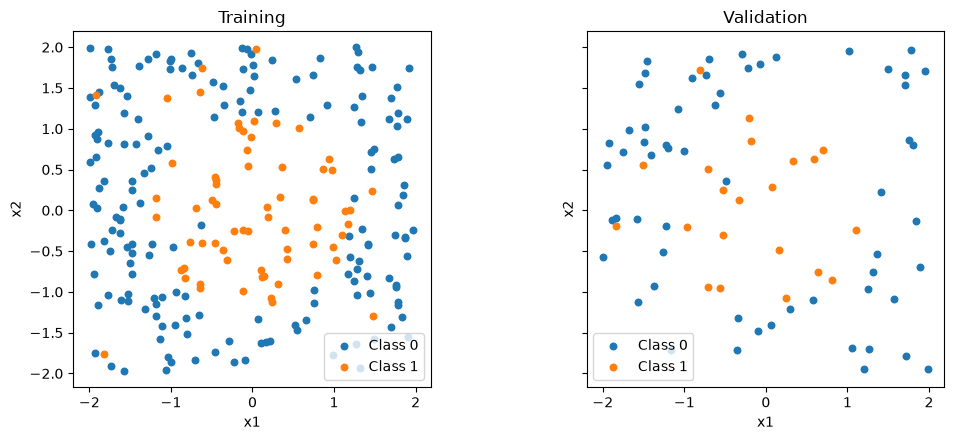

In [2]:
rng = random.Random(14)
locations, labels = [], []
for i in range(320):
    x1, x2 = rng.uniform(-2, 2), rng.uniform(-2, 2)
    label = int(x1*x1 + x2*x2 < 1.45)
    if rng.random() < 0.05:
        label = 1-label
    locations.append([x1, x2])
    labels.append(label)

X_class = torch.tensor(locations, dtype=torch.float32, device=device)
y_class = torch.tensor(labels, dtype=torch.float32, device=device).reshape(-1, 1)
indices = list(range(len(labels)))
random.Random(14).shuffle(indices)
cut = int(0.75 * len(indices))
X_ct, y_ct = X_class[indices[:cut]], y_class[indices[:cut]]
X_cv, y_cv = X_class[indices[cut:]], y_class[indices[cut:]]
print('Training tensors:', X_ct.shape, y_ct.shape, X_ct.device)
print('Validation tensors:', X_cv.shape, y_cv.shape, X_cv.device)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
for ax, X, y, title in [(axes[0], X_ct, y_ct, 'Training'), (axes[1], X_cv, y_cv, 'Validation')]:
    for label in (0, 1):
        points = X[y[:, 0] == label].cpu().numpy()
        ax.scatter(points[:, 0], points[:, 1], s=22, label=f'Class {label}')
    ax.set(title=title, xlabel='x1', ylabel='x2', aspect='equal')
    ax.legend()
plt.tight_layout()
plt.show()

## A2. Build the neural network with `torch.nn`

For hidden neuron $j$:

$$z_j=w_{j1}x_1+w_{j2}x_2+b_j,\qquad h_j=\tanh(z_j).$$

The output score is

$$s=v_1h_1+v_2h_2+\cdots+v_6h_6+c.$$

`nn.Linear(2, 6)` provides hidden weighted sums and biases. `nn.Tanh()` applies the activation. `nn.Linear(6, 1)` provides the output score. `nn.Sequential` connects them in order. `.to(device)` places the parameters on the same device as the data.

The model returns a **logit**, not a probability. For reporting probabilities, apply $\hat y=\sigma(s)$. The loss in the next section performs sigmoid internally.

There are $6(2+1)+(6+1)=25$ trainable parameters. PyTorch stores these in the layer objects. We do not create Python lists of weights or calculate weighted sums ourselves. PyTorch's default Linear initialization is used; its initial values differ from the from-scratch notebook.

In [3]:
torch.manual_seed(5)
classifier = nn.Sequential(
    nn.Linear(in_features=2, out_features=6),
    nn.Tanh(),
    nn.Linear(in_features=6, out_features=1),
).to(device)
print(classifier)
print('Model type:', type(classifier))
print('Model device:', next(classifier.parameters()).device)
print('Trainable parameters:', sum(p.numel() for p in classifier.parameters()))
assert sum(p.numel() for p in classifier.parameters()) == 25

Sequential(
  (0): Linear(in_features=2, out_features=6, bias=True)
  (1): Tanh()
  (2): Linear(in_features=6, out_features=1, bias=True)
)
Model type: <class 'torch.nn.modules.container.Sequential'>
Model device: cuda:0
Trainable parameters: 25


## A3. Choose the loss and optimizer

Binary cross-entropy is

$$\ell=-y\log(\hat y)-(1-y)\log(1-\hat y).$$

`nn.BCEWithLogitsLoss()` combines sigmoid and binary cross-entropy numerically stably. Supply raw output logits; do **not** put a sigmoid before this loss.

`torch.optim.SGD` uses gradient descent without momentum here:

$$\text{parameter}\leftarrow\text{parameter}-\eta\frac{\partial L}{\partial\text{parameter}}.$$

The optimizer receives `classifier.parameters()`, so it knows which trainable tensors to update.

In [4]:
classification_loss = nn.BCEWithLogitsLoss()
classification_optimizer = torch.optim.SGD(classifier.parameters(), lr=0.12)
print('Loss:', classification_loss)
print('Optimizer:', type(classification_optimizer).__name__)

Loss: BCEWithLogitsLoss()
Optimizer: SGD


## A4. Train with PyTorch automatic differentiation

Each epoch performs one full-batch update:
1. `train()` selects training mode.
2. `zero_grad()` clears previous gradients, because PyTorch accumulates them.
3. `classifier(X_ct)` performs forward propagation.
4. The loss function measures error.
5. `loss.backward()` computes derivatives automatically.
6. `optimizer.step()` updates weights using those derivatives.

For sigmoid plus binary cross-entropy, the output-score derivative contains $\hat y-y$. Hidden derivatives contain the chain-rule factor $1-h_j^2$. PyTorch calculates these derivatives; we do not implement the derivative formulas.

After the update, evaluate **both** splits at the same weights. `eval()` selects evaluation mode; `torch.no_grad()` disables gradient tracking. Validation never enters `backward()`.

With Linear and Tanh only, train/eval mode does not change the numerical operations. The distinction remains important for models that later include dropout or batch normalization.

In [5]:
classification_epochs = 1800
class_training_losses, class_validation_losses = [], []

for epoch in range(1, classification_epochs + 1):
    classifier.train()
    classification_optimizer.zero_grad()
    logits = classifier(X_ct)
    loss = classification_loss(logits, y_ct)
    loss.backward()
    classification_optimizer.step()

    classifier.eval()
    with torch.no_grad():
        training_loss = classification_loss(classifier(X_ct), y_ct).item()
        validation_loss = classification_loss(classifier(X_cv), y_cv).item()
    class_training_losses.append(training_loss)
    class_validation_losses.append(validation_loss)
    print(f'Epoch {epoch:4d}/{classification_epochs} | training: {training_loss:.6f} | validation: {validation_loss:.6f}')

Epoch    1/1800 | training: 0.803183 | validation: 0.823744
Epoch    2/1800 | training: 0.786555 | validation: 0.806225
Epoch    3/1800 | training: 0.771505 | validation: 0.790344
Epoch    4/1800 | training: 0.757860 | validation: 0.775919
Epoch    5/1800 | training: 0.745468 | validation: 0.762792
Epoch    6/1800 | training: 0.734194 | validation: 0.750822
Epoch    7/1800 | training: 0.723922 | validation: 0.739888
Epoch    8/1800 | training: 0.714548 | validation: 0.729881
Epoch    9/1800 | training: 0.705979 | validation: 0.720706
Epoch   10/1800 | training: 0.698136 | validation: 0.712279
Epoch   11/1800 | training: 0.690946 | validation: 0.704527
Epoch   12/1800 | training: 0.684345 | validation: 0.697383
Epoch   13/1800 | training: 0.678278 | validation: 0.690789
Epoch   14/1800 | training: 0.672693 | validation: 0.684693
Epoch   15/1800 | training: 0.667546 | validation: 0.679050
Epoch   16/1800 | training: 0.662797 | validation: 0.673817
Epoch   17/1800 | training: 0.658410 | v

## A5. Plot training and validation loss

Both histories are post-update losses. Smaller binary cross-entropy indicates a better match between the predicted probabilities and observed labels.

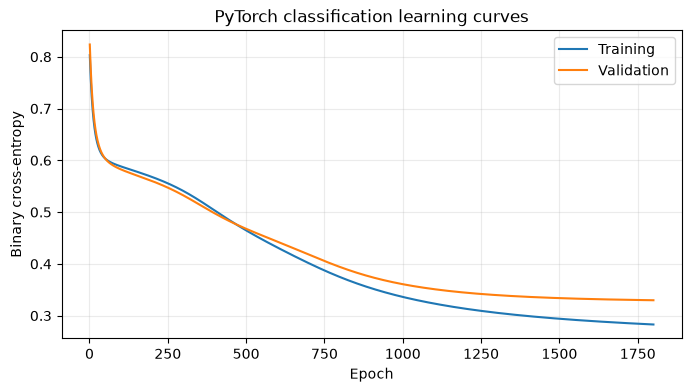

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
epoch_numbers = range(1, classification_epochs+1)
ax.plot(epoch_numbers, class_training_losses, label='Training')
ax.plot(epoch_numbers, class_validation_losses, label='Validation')
ax.set(title='PyTorch classification learning curves', xlabel='Epoch', ylabel='Binary cross-entropy')
ax.legend()
ax.grid(alpha=0.25)
plt.show()

## A6. Report binary-classification metrics

Use `torch.sigmoid` to obtain probabilities. Predict class 1 at probability at least 0.5. Class 1 is positive.

$$\mathrm{accuracy}=\frac{TP+TN}{N},\quad\mathrm{precision}=\frac{TP}{TP+FP},\quad\mathrm{recall}=\frac{TP}{TP+FN}.$$

$$\mathrm{specificity}=\frac{TN}{TN+FP},\quad F_1=\frac{2TP}{2TP+FP+FN}.$$

The metric arithmetic below summarizes predictions; it is not a manually implemented learning algorithm. Zero denominators return zero. The table includes both splits.

In [7]:
rows = ['| Metric | Training | Validation |', '|---|---:|---:|']
results = []
classifier.eval()
with torch.no_grad():
    for X, targets in [(X_ct, y_ct), (X_cv, y_cv)]:
        probabilities = torch.sigmoid(classifier(X)).reshape(-1)
        predicted = probabilities >= 0.5
        positive = targets.reshape(-1) == 1
        tp = int((predicted & positive).sum().item())
        tn = int((~predicted & ~positive).sum().item())
        fp = int((predicted & ~positive).sum().item())
        fn = int((~predicted & positive).sum().item())
        precision = tp/(tp+fp) if tp+fp else 0.0
        recall = tp/(tp+fn) if tp+fn else 0.0
        specificity = tn/(tn+fp) if tn+fp else 0.0
        f1 = 2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 0.0
        results.append([(tp+tn)/len(targets), precision, recall, specificity, f1, tp, tn, fp, fn])
for name, tr, va in zip(['Accuracy','Precision','Recall','Specificity','F1','TP','TN','FP','FN'], results[0], results[1]):
    rows.append(f'| {name} | {tr:.4f} | {va:.4f} |' if name not in ('TP','TN','FP','FN')
                else f'| {name} | {tr} | {va} |')
display(Markdown('\n'.join(rows)))

| Metric | Training | Validation |
|---|---:|---:|
| Accuracy | 0.8917 | 0.8750 |
| Precision | 0.9767 | 0.8235 |
| Recall | 0.6269 | 0.6667 |
| Specificity | 0.9942 | 0.9492 |
| F1 | 0.7636 | 0.7368 |
| TP | 42 | 14 |
| TN | 172 | 56 |
| FP | 1 | 3 |
| FN | 25 | 7 |

## A7. Plot the learned probability region

Use one PyTorch model call to predict a grid. The black contour is probability 0.5. Circles are training observations; outlined squares are validation observations.

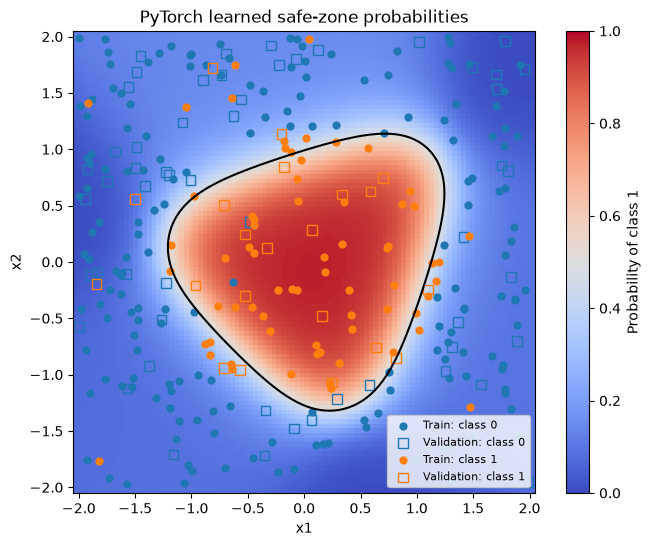

In [8]:
coordinates = np.linspace(-2.05, 2.05, 100, dtype=np.float32)
grid_x, grid_y = np.meshgrid(coordinates, coordinates)
grid_points = torch.tensor(np.column_stack([grid_x.ravel(), grid_y.ravel()]), device=device)
classifier.eval()
with torch.no_grad():
    grid_probabilities = torch.sigmoid(classifier(grid_points)).cpu().numpy().reshape(grid_x.shape)
fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(grid_probabilities, origin='lower', extent=(-2.05,2.05,-2.05,2.05), cmap='coolwarm', vmin=0, vmax=1)
ax.contour(grid_x, grid_y, grid_probabilities, levels=[0.5], colors='black')
for label, color in [(0,'tab:blue'), (1,'tab:orange')]:
    for X, y, split in [(X_ct,y_ct,'Train'), (X_cv,y_cv,'Validation')]:
        points = X[y[:,0] == label].cpu().numpy()
        ax.scatter(points[:,0], points[:,1], marker='o' if split=='Train' else 's',
                   facecolors=color if split=='Train' else 'none', edgecolors=color,
                   s=24 if split=='Train' else 48, label=f'{split}: class {label}')
ax.set(title='PyTorch learned safe-zone probabilities', xlabel='x1', ylabel='x2')
ax.legend(fontsize=8)
fig.colorbar(image, ax=ax, label='Probability of class 1')
plt.show()

# Example B — Nonlinear regression
## B1. Prepare the measured calibration observations

Use the same noisy data and split as before. Plot only measured points, not the noise-free generating function. The two architectures share this split.

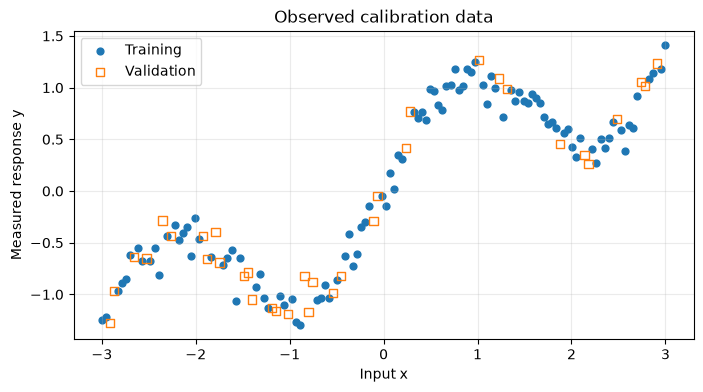

In [9]:
rng = random.Random(31)
measurements, responses = [], []
for i in range(140):
    x = -3 + 6*i/139
    measurements.append([x])
    responses.append(0.5*x + 0.7*math.sin(2*x) + rng.gauss(0,0.11))
X_reg = torch.tensor(measurements, dtype=torch.float32, device=device)
y_reg = torch.tensor(responses, dtype=torch.float32, device=device).reshape(-1,1)
indices = list(range(len(responses)))
random.Random(31).shuffle(indices)
cut = int(0.75*len(indices))
X_rt, y_rt = X_reg[indices[:cut]], y_reg[indices[:cut]]
X_rv, y_rv = X_reg[indices[cut:]], y_reg[indices[cut:]]
fig, ax = plt.subplots(figsize=(8,4))
ax.scatter(X_rt[:,0].cpu().numpy(), y_rt[:,0].cpu().numpy(), s=24, label='Training')
ax.scatter(X_rv[:,0].cpu().numpy(), y_rv[:,0].cpu().numpy(), marker='s', facecolors='none', edgecolors='tab:orange', label='Validation')
ax.set(title='Observed calibration data', xlabel='Input x', ylabel='Measured response y')
ax.legend()
ax.grid(alpha=0.25)
plt.show()

## B2. Build the two-neuron baseline directly with PyTorch

The regression output is the score itself: $\hat y=v_1h_1+v_2h_2+c$. Do not apply sigmoid: responses may be negative or exceed 1.

`nn.MSELoss()` measures ordinary mean squared error:

$$L=\frac1N\sum_{i=1}^{N}(\hat y_i-y_i)^2.$$

The from-scratch notebook used half MSE. Set the learning rate to 0.025, half the old 0.05, for a comparable derivative/update scale. Initialization still differs. The baseline has $2(1+1)+(2+1)=7$ parameters.

In [10]:
torch.manual_seed(9)
baseline = nn.Sequential(nn.Linear(1,2), nn.Tanh(), nn.Linear(2,1)).to(device)
regression_loss = nn.MSELoss()
baseline_optimizer = torch.optim.SGD(baseline.parameters(), lr=0.025)
print(baseline)
print('Baseline device:', next(baseline.parameters()).device)
print('Baseline parameters:', sum(p.numel() for p in baseline.parameters()))

Sequential(
  (0): Linear(in_features=1, out_features=2, bias=True)
  (1): Tanh()
  (2): Linear(in_features=2, out_features=1, bias=True)
)
Baseline device: cuda:0
Baseline parameters: 7


## B3. Train the baseline

The full-batch PyTorch training sequence is the same as in classification. Run 8,000 epochs, reporting both post-update losses every epoch. This deliberately produces long output.

In [11]:
regression_epochs = 8000
small_training_losses, small_validation_losses = [], []
for epoch in range(1, regression_epochs+1):
    baseline.train()
    baseline_optimizer.zero_grad()
    predictions = baseline(X_rt)
    loss = regression_loss(predictions, y_rt)
    loss.backward()
    baseline_optimizer.step()
    baseline.eval()
    with torch.no_grad():
        tr = regression_loss(baseline(X_rt), y_rt).item()
        va = regression_loss(baseline(X_rv), y_rv).item()
    small_training_losses.append(tr)
    small_validation_losses.append(va)
    print(f'Epoch {epoch:4d}/{regression_epochs} | training: {tr:.6f} | validation: {va:.6f}')

Epoch    1/8000 | training: 0.632846 | validation: 0.643416
Epoch    2/8000 | training: 0.574052 | validation: 0.591439
Epoch    3/8000 | training: 0.523354 | validation: 0.546142
Epoch    4/8000 | training: 0.479549 | validation: 0.506565
Epoch    5/8000 | training: 0.441617 | validation: 0.471895
Epoch    6/8000 | training: 0.408690 | validation: 0.441439
Epoch    7/8000 | training: 0.380033 | validation: 0.414603
Epoch    8/8000 | training: 0.355021 | validation: 0.390884
Epoch    9/8000 | training: 0.333126 | validation: 0.369853
Epoch   10/8000 | training: 0.313902 | validation: 0.351143
Epoch   11/8000 | training: 0.296972 | validation: 0.334448
Epoch   12/8000 | training: 0.282018 | validation: 0.319502
Epoch   13/8000 | training: 0.268771 | validation: 0.306085
Epoch   14/8000 | training: 0.257003 | validation: 0.294006
Epoch   15/8000 | training: 0.246521 | validation: 0.283103
Epoch   16/8000 | training: 0.237160 | validation: 0.273237
Epoch   17/8000 | training: 0.228781 | v

## B4. Inspect baseline learning curves and fit

Draw both losses, then overlay the PyTorch model's predictions on the observed points.

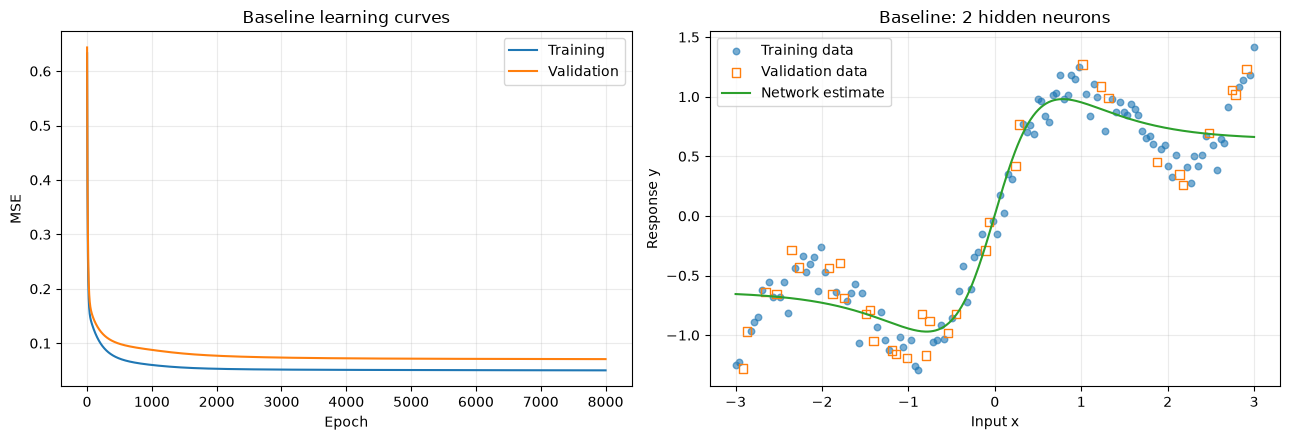

In [12]:
fig, axes = plt.subplots(1,2,figsize=(13,4.5))
axes[0].plot(range(1,regression_epochs+1), small_training_losses, label='Training')
axes[0].plot(range(1,regression_epochs+1), small_validation_losses, label='Validation')
axes[0].set(title='Baseline learning curves', xlabel='Epoch', ylabel='MSE')
curve_x = torch.linspace(-3, 3, 400, device=device).reshape(-1, 1)
baseline.eval()
with torch.no_grad():
    small_curve = baseline(curve_x).cpu().numpy().reshape(-1)
axes[1].scatter(X_rt[:,0].cpu().numpy(), y_rt[:,0].cpu().numpy(), s=22, alpha=0.6, label='Training data')
axes[1].scatter(X_rv[:,0].cpu().numpy(), y_rv[:,0].cpu().numpy(), facecolors='none', edgecolors='tab:orange', marker='s', label='Validation data')
axes[1].plot(curve_x[:,0].cpu().numpy(), small_curve, color='tab:green', label='Network estimate')
axes[1].set(title='Baseline: 2 hidden neurons', xlabel='Input x', ylabel='Response y')
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## B5. Build and train an eight-neuron architecture

Change the hidden width; keep the data split, optimizer, learning rate, and epoch count unchanged. Matching seeds does not make the initial parameter sets identical for different widths. More capacity can help, but validation improvement must be measured rather than assumed.

The larger model has 25 trainable parameters.

Sequential(
  (0): Linear(in_features=1, out_features=8, bias=True)
  (1): Tanh()
  (2): Linear(in_features=8, out_features=1, bias=True)
)
Larger-model device: cuda:0
Larger-model parameters: 25
Epoch    1/8000 | training: 0.288500 | validation: 0.256423
Epoch    2/8000 | training: 0.259140 | validation: 0.231012
Epoch    3/8000 | training: 0.236961 | validation: 0.212311
Epoch    4/8000 | training: 0.220124 | validation: 0.198524
Epoch    5/8000 | training: 0.207274 | validation: 0.188347
Epoch    6/8000 | training: 0.197409 | validation: 0.180827
Epoch    7/8000 | training: 0.189788 | validation: 0.175268
Epoch    8/8000 | training: 0.183858 | validation: 0.171159
Epoch    9/8000 | training: 0.179209 | validation: 0.168125
Epoch   10/8000 | training: 0.175534 | validation: 0.165888
Epoch   11/8000 | training: 0.172601 | validation: 0.164245
Epoch   12/8000 | training: 0.170239 | validation: 0.163044
Epoch   13/8000 | training: 0.168317 | validation: 0.162172
Epoch   14/8000 | traini

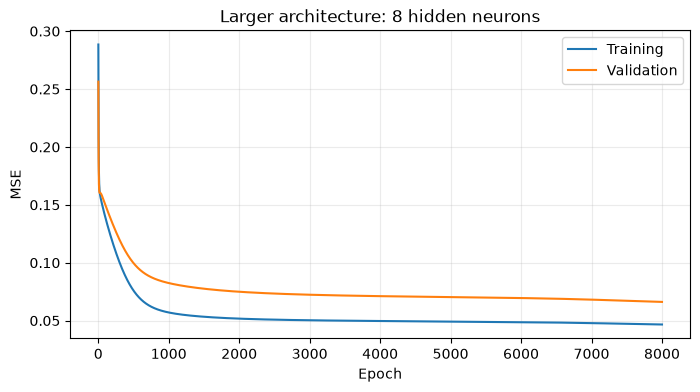

In [13]:
torch.manual_seed(9)
larger = nn.Sequential(nn.Linear(1,8), nn.Tanh(), nn.Linear(8,1)).to(device)
larger_optimizer = torch.optim.SGD(larger.parameters(), lr=0.025)
print(larger)
print('Larger-model device:', next(larger.parameters()).device)
print('Larger-model parameters:', sum(p.numel() for p in larger.parameters()))
large_training_losses, large_validation_losses = [], []
for epoch in range(1,regression_epochs+1):
    larger.train()
    larger_optimizer.zero_grad()
    predictions = larger(X_rt)
    loss = regression_loss(predictions, y_rt)
    loss.backward()
    larger_optimizer.step()
    larger.eval()
    with torch.no_grad():
        tr = regression_loss(larger(X_rt), y_rt).item()
        va = regression_loss(larger(X_rv), y_rv).item()
    large_training_losses.append(tr)
    large_validation_losses.append(va)
    print(f'Epoch {epoch:4d}/{regression_epochs} | training: {tr:.6f} | validation: {va:.6f}')
fig, ax = plt.subplots(figsize=(8,4))
ax.plot(range(1,regression_epochs+1), large_training_losses, label='Training')
ax.plot(range(1,regression_epochs+1), large_validation_losses, label='Validation')
ax.set(title='Larger architecture: 8 hidden neurons', xlabel='Epoch', ylabel='MSE')
ax.legend()
ax.grid(alpha=0.25)
plt.show()

## B6. Compare fitted curves and final metrics

Shared axes make the visual comparison fair. Evaluate both splits at the final weights. RMSE is the square root of MSE and uses the response's units.

Validation informs architecture selection; an independent final performance estimate would need an untouched test set.

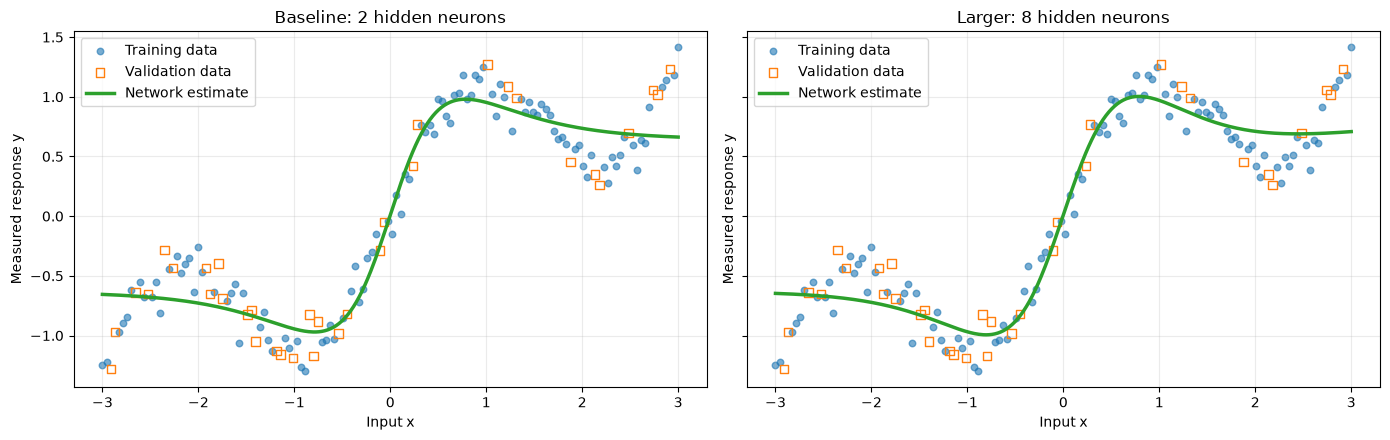

| Architecture | Training MSE | Validation MSE | Training RMSE | Validation RMSE |
|---|---:|---:|---:|---:|
| 2 hidden neurons | 0.05016 | 0.07081 | 0.22397 | 0.26610 |
| 8 hidden neurons | 0.04664 | 0.06615 | 0.21596 | 0.25720 |

Validation MSE reduction with the wider model: 6.58%
A negative value means validation performance became worse.


In [14]:
baseline.eval()
larger.eval()
with torch.no_grad():
    large_curve = larger(curve_x).cpu().numpy().reshape(-1)
fig, axes = plt.subplots(1,2,figsize=(14,4.5),sharex=True,sharey=True)
for ax, curve, title in [(axes[0],small_curve,'Baseline: 2 hidden neurons'),
                         (axes[1],large_curve,'Larger: 8 hidden neurons')]:
    ax.scatter(X_rt[:,0].cpu().numpy(), y_rt[:,0].cpu().numpy(), s=22, alpha=0.6, label='Training data')
    ax.scatter(X_rv[:,0].cpu().numpy(), y_rv[:,0].cpu().numpy(), marker='s', facecolors='none', edgecolors='tab:orange', label='Validation data')
    ax.plot(curve_x[:,0].cpu().numpy(), curve, color='tab:green', linewidth=2.5, label='Network estimate')
    ax.set(title=title,xlabel='Input x',ylabel='Measured response y')
    ax.legend()
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()
rows = ['| Architecture | Training MSE | Validation MSE | Training RMSE | Validation RMSE |',
        '|---|---:|---:|---:|---:|']
validation_results = []
with torch.no_grad():
    for name, model in [('2 hidden neurons',baseline),('8 hidden neurons',larger)]:
        tr = regression_loss(model(X_rt),y_rt).item()
        va = regression_loss(model(X_rv),y_rv).item()
        validation_results.append(va)
        rows.append(f'| {name} | {tr:.5f} | {va:.5f} | {math.sqrt(tr):.5f} | {math.sqrt(va):.5f} |')
display(Markdown('\n'.join(rows)))
reduction = 100*(validation_results[0]-validation_results[1])/validation_results[0]
print(f'Validation MSE reduction with the wider model: {reduction:.2f}%')
print('A negative value means validation performance became worse.')

## Review: find the PyTorch operations

1. Locate the layer that creates each set of trainable weights.
2. Which model call replaces handwritten forward propagation?
3. Which call computes the gradients automatically?
4. Which call changes the parameters?
5. Why do gradients need clearing every epoch?
6. Why do we use both `eval()` and `no_grad()`?
7. Where is sigmoid applied, and why is it absent before `BCEWithLogitsLoss`?
8. Did increasing hidden width improve validation performance?

The essential package-based sequence is:

```python
optimizer.zero_grad()
predictions = model(training_inputs)
loss = loss_function(predictions, training_targets)
loss.backward()
optimizer.step()
```

There are no manually implemented neuron derivatives or weight updates in this notebook.